# Regression 

Regression is where models predict a number.

In ML, the goal of regression is to create a model that can predict a numeric, quantifiable value, such as a price, amount, size or other scalar number.

Regression is a statistical technique of fundamental importance to science because of its ease of interpretation, robustmess and speed in calculation. Regression models provide an excellent foundation for understanding how more complex machine learning techniques work. 

Regression works by establishing a relationship between variables in the data that represent characteristics- known as the features- of the thing being observed, and the variable we are trying to predict are known as the label. 

To train the model, we start with a data sample containing the features, as well as known values for the label.

We will split this data sample into two subsets:
A training dataset to which we will apply an algorithm that determines a function encapsulating the relationship between the feature values and the known label values. 

A validation or test dataset that we can use to evaluate the model by using it to generate predictions for the label and comparing them to the actual known label values.



In [2]:
import pandas as pd

bike_data= pd.read_csv('daily-bike-share.csv')

bike_data.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,rentals
0,1,1/1/2011,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331
1,2,1/2/2011,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131
2,3,1/3/2011,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120
3,4,1/4/2011,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108
4,5,1/5/2011,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82


The data consists of the following columns:

**instant**: A unique row identifier

**dteday**: The date on which the data was observed; in this case, the data was collected daily, so there's one row per date.

**season**: A numerically encoded value indicating the season (1:winter, 2:spring, 3:summer, 4:fall)

**yr**: The year of the study in which the observation was made (the study took place over two years: year 0 represents 2011, and year 1 represents 2012)

**mnth**: The calendar month in which the observation was made (1:January ... 12:December)

**holiday**: A binary value indicating whether or not the observation was made on a public holiday)

**weekday**: The day of the week on which the observation was made (0:Sunday ... 6:Saturday)

**workingday**: A binary value indicating whether or not the day is a working day (not a weekend or holiday)

**weathersit**: A categorical value indicating the weather situation (1:clear, 2:mist/cloud, 3:light rain/snow, 4:heavy rain/hail/snow/fog)

**temp**: The temperature in celsius (normalized)

**atemp**: The apparent ("feels-like") temperature in celsius (normalized)

**hum**: The humidity level (normalized)

**windspeed**: The windspeed (normalized)

**rentals**: The number of bicycle rentals recorded.



Supervised machine learning techniques involves training a model to operate on a set of features and predict label using a dataset that includes some already known label values. The training process fits the features to the known labels to define a general function that can be applied to new features for which the labels are unknown. 


The goal of training a model is to find function that performs the some kind of calculation to the x values that produces y results. 

Supervised machine learning algorithms are mainly divided in two types:

**Regression Algorithms:** Algorithms that predict y value that is a numeric value. 

**Classification Algorithms:** Algorithms that predict to which category or class an observation belongs. 


In [3]:
bike_data.day = pd.DatetimeIndex(bike_data.dteday).day
bike_data.head()

/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_13211/1124757452.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  bike_data.day = pd.DatetimeIndex(bike_data.dteday).day


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,rentals
0,1,1/1/2011,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331
1,2,1/2/2011,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131
2,3,1/3/2011,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120
3,4,1/4/2011,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108
4,5,1/5/2011,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82


In [5]:
numeric_features = ['temp', 'atemp', 'hum', 'windspeed']
bike_data[numeric_features + ['rentals']].describe()


,temp,atemp,hum,windspeed,rentals
count,731.000000,731.000000,731.000000,731.000000,731.000000
mean,0.495385,0.474354,0.627894,0.190486,848.176471
std,0.183051,0.162961,0.142429,0.077498,686.622488
min,0.059130,0.079070,0.000000,0.022392,2.000000
25%,0.337083,0.337842,0.520000,0.134950,315.500000
50%,0.498333,0.486733,0.626667,0.180975,713.000000
75%,0.655417,0.608602,0.730209,0.233214,1096.000000
max,0.861667,0.840896,0.972500,0.507463,3410.000000


/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_13211/3341567286.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


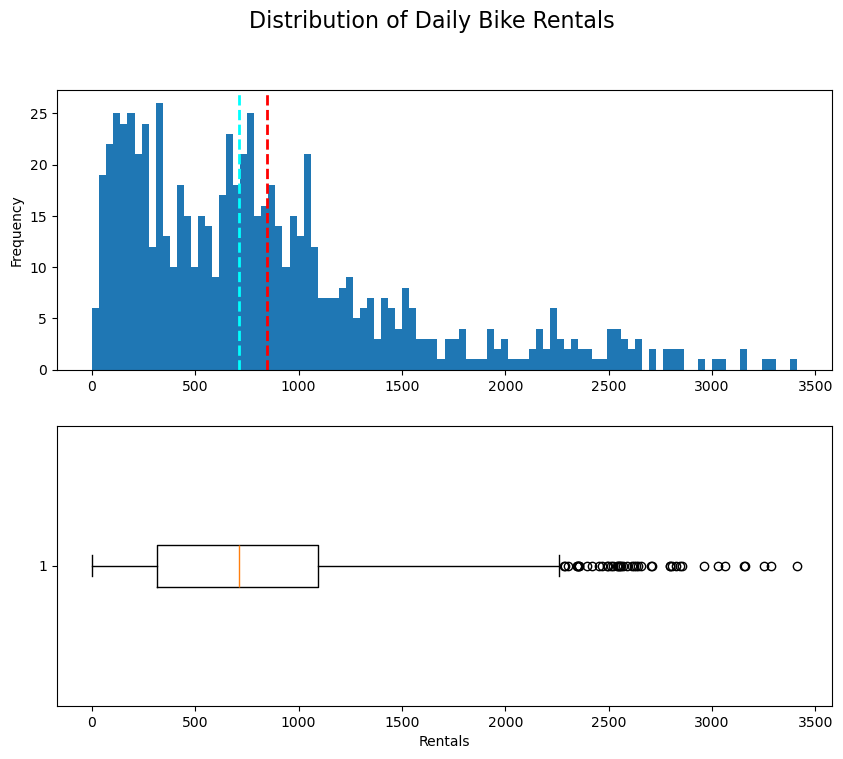

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

label = bike_data['rentals']

fig, ax = plt.subplots(2, 1, figsize=(10, 8))

ax[0].hist(label, bins=100)
ax[0].set_ylabel('Frequency')

ax[0].axvline(label.mean(), color='red', linestyle='dashed', linewidth=2)
ax[0].axvline(label.median(), color='cyan', linestyle='dashed', linewidth=2)

ax[1].boxplot(label, vert=False)
ax[1].set_xlabel('Rentals')

fig.suptitle('Distribution of Daily Bike Rentals', fontsize=16)

fig.show()



/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_13211/3637949194.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


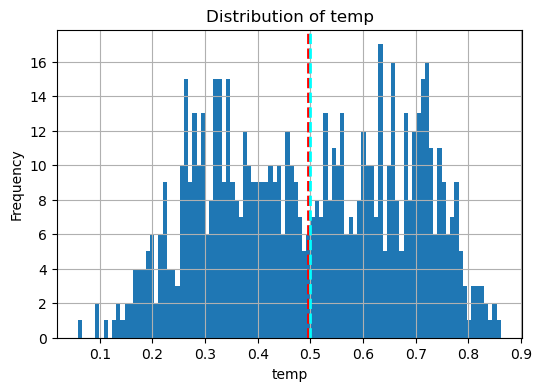

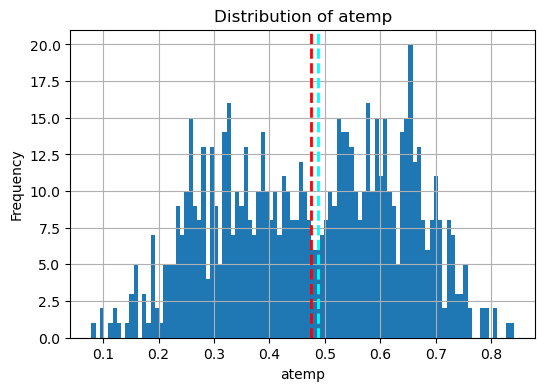

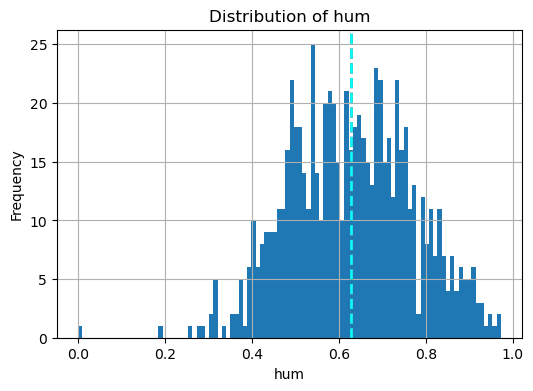

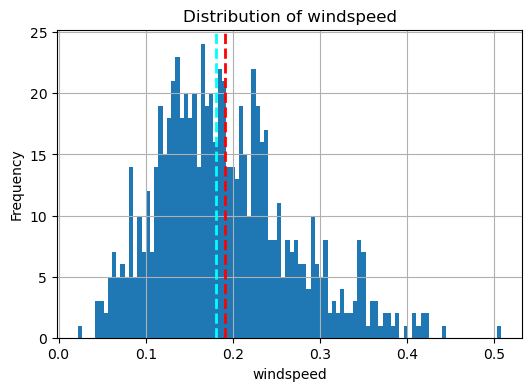

In [7]:
for col in numeric_features:
    fig = plt.figure(figsize=(6, 4))
    ax = fig.gca()
    feature = bike_data[col]
    feature.hist(bins=100, ax=ax)
    ax.axvline(feature.mean(), color='red', linestyle='dashed', linewidth=2)
    ax.axvline(feature.median(), color='cyan', linestyle='dashed', linewidth=2)
    ax.set_title(f'Distribution of {col}')
    ax.set_ylabel('Frequency')
    ax.set_xlabel(col)

fig.show()


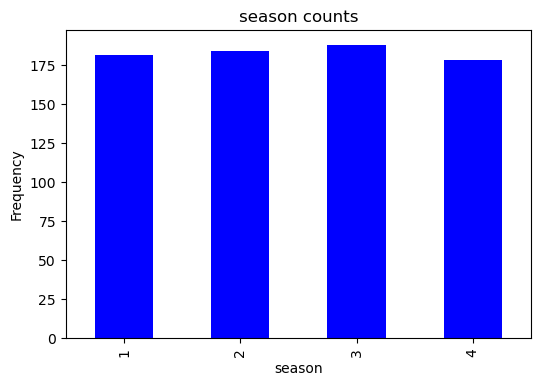

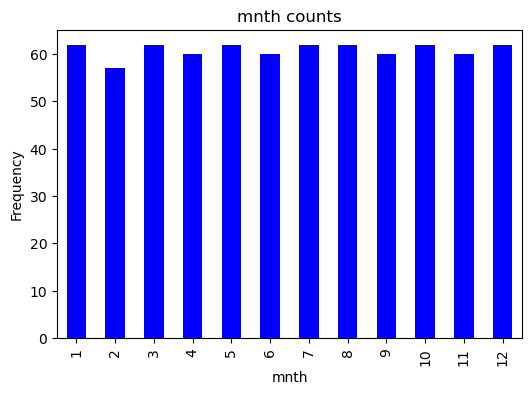

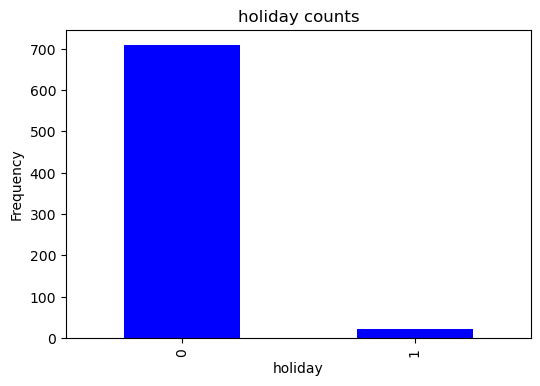

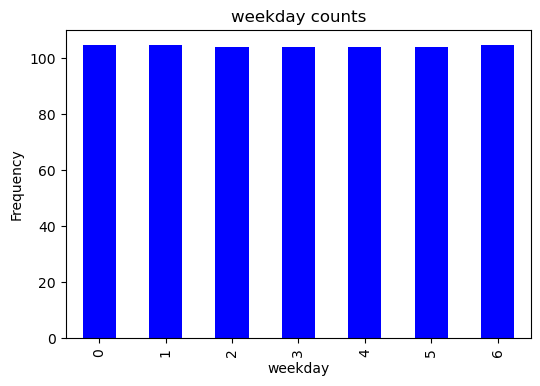

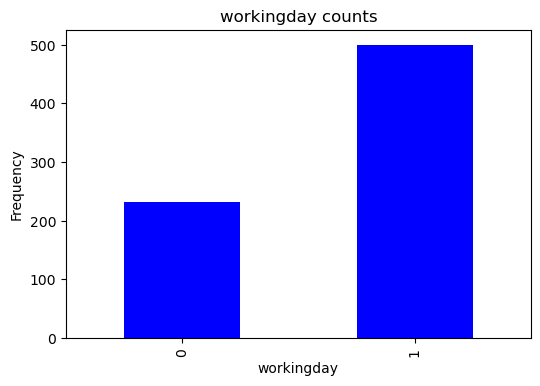

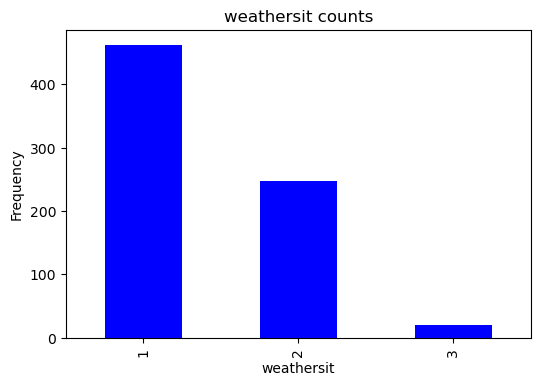

In [8]:
import numpy as np

categorical_features = ['season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']

for col in categorical_features:
    counts = bike_data[col].value_counts().sort_index()
    fig = plt.figure(figsize=(6, 4))
    ax = fig.gca()
    counts.plot(kind='bar', ax=ax, color='blue')
    ax.set_title(col + ' counts')
    ax.set_ylabel('Frequency')
    ax.set_xlabel(col)

plt.show()


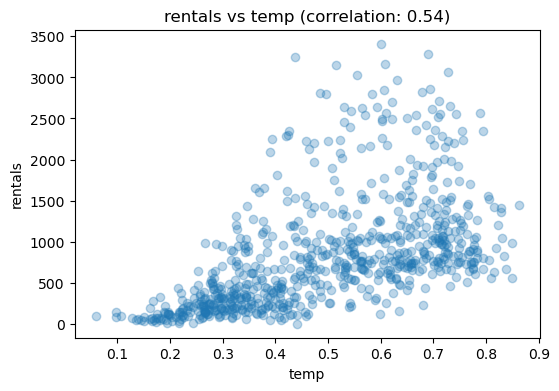

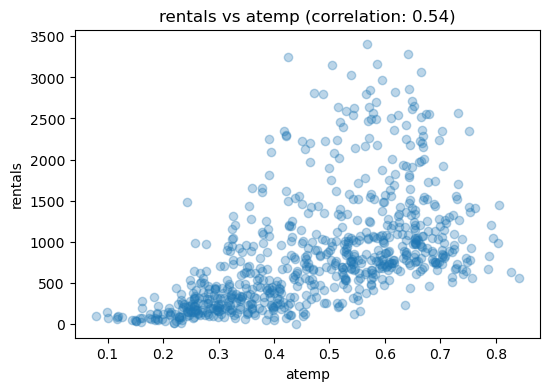

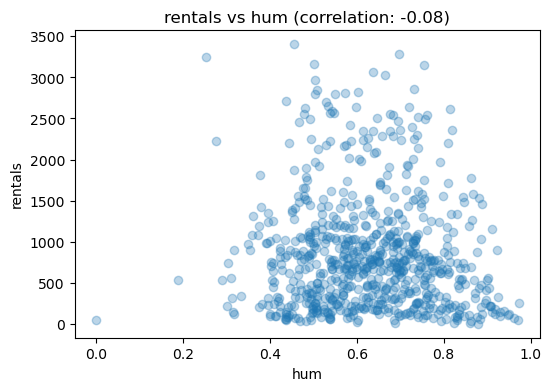

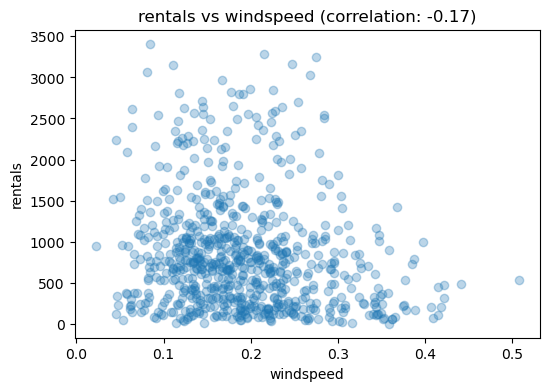

In [9]:
for col in numeric_features:
    fig = plt.figure(figsize=(6, 4))
    ax = fig.gca()
    feature = bike_data[col]
    label = bike_data['rentals']
    correlation = feature.corr(label)
    plt.scatter(x=feature, y=label, alpha=0.3)
    plt.xlabel(col)
    plt.ylabel('rentals')
    plt.title(f'rentals vs {col} (correlation: {correlation:.2f})')

plt.show()


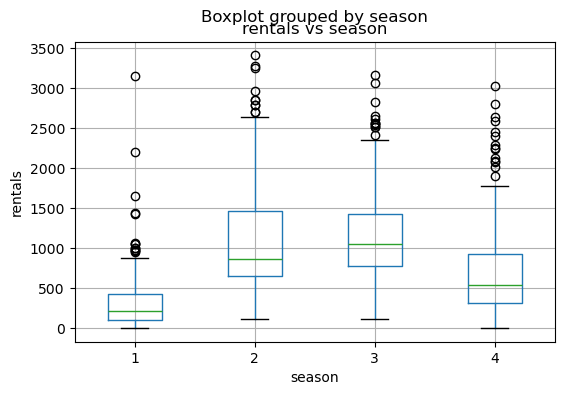

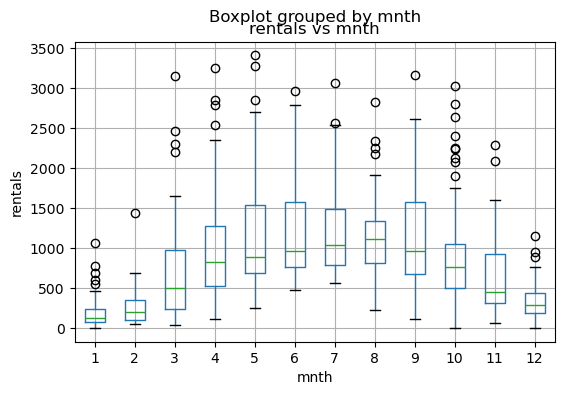

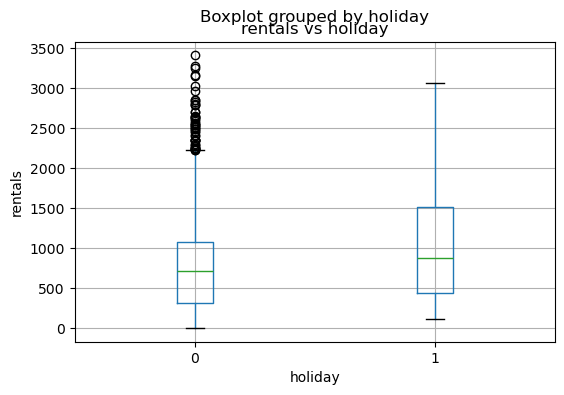

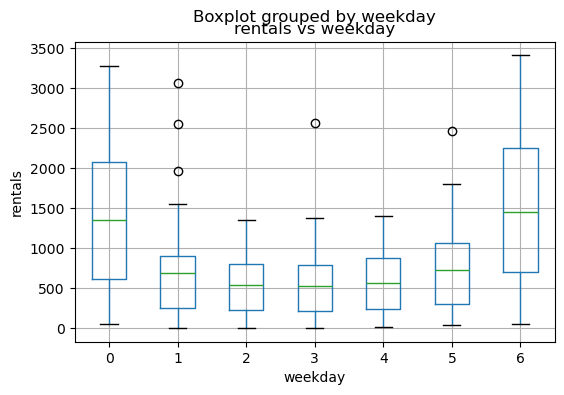

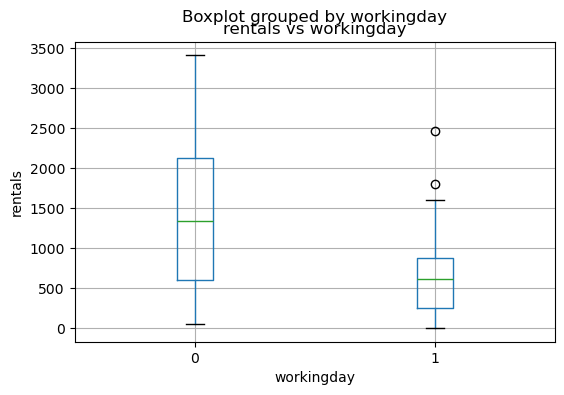

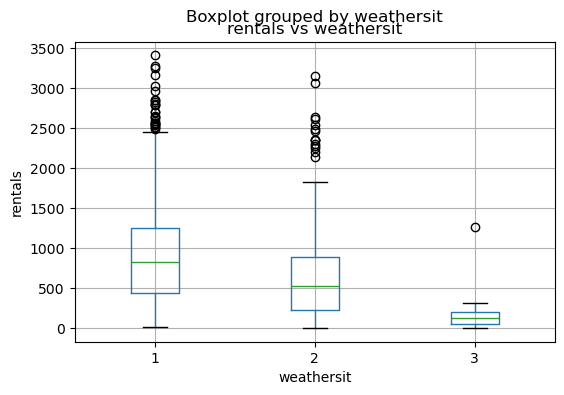

In [10]:
for col in categorical_features:
    fig = plt.figure(figsize=(6, 4))
    ax = fig.gca()
    bike_data.boxplot(column='rentals', by=col, ax=ax)    
    ax.set_title(f'rentals vs {col}')
    ax.set_ylabel('rentals')
    ax.set_xlabel(col)

plt.show()

In [11]:
# Train a regression model

# Seperate features and label
X, y = bike_data[['season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit','temp', 'atemp', 'hum', 'windspeed']].values, bike_data['rentals'].values

print('Features: ', X[:10], '\nLabels: ', y[:10],sep='\n')


Features: 
[[1.        1.        0.        6.        0.        2.        0.344167
  0.363625  0.805833  0.160446 ]
 [1.        1.        0.        0.        0.        2.        0.363478
  0.353739  0.696087  0.248539 ]
 [1.        1.        0.        1.        1.        1.        0.196364
  0.189405  0.437273  0.248309 ]
 [1.        1.        0.        2.        1.        1.        0.2
  0.212122  0.590435  0.160296 ]
 [1.        1.        0.        3.        1.        1.        0.226957
  0.22927   0.436957  0.1869   ]
 [1.        1.        0.        4.        1.        1.        0.204348
  0.233209  0.518261  0.0895652]
 [1.        1.        0.        5.        1.        2.        0.196522
  0.208839  0.498696  0.168726 ]
 [1.        1.        0.        6.        0.        2.        0.165
  0.162254  0.535833  0.266804 ]
 [1.        1.        0.        0.        0.        1.        0.138333
  0.116175  0.434167  0.36195  ]
 [1.        1.        0.        1.        1.        1.       

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=0)

print(f'Training set: { X_train.shape[0]} samples\nTest set: {X_test.shape[0]} samples')


Training set: 511 samples
Test set: 220 samples


In [ ]:
# Train the model
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(X_train, y_train)
print(model)


LinearRegression()


In [14]:
# Evaluate the Trained model

import numpy as np

predictions = model.predict(X_test)
np.set_printoptions(suppress=True)
print('Predictions: ', predictions[:10], sep='\n')
print('Actual values: ', y_test[:10], sep='\n')

Predictions: 
[1895.66782612 1183.91334853 1006.76381203  -27.72524904  313.62301448
  385.40476901  474.54590338  589.58044986 1476.48323136  -21.99577138]
Actual values: 
[2418  754  222   47  244  145  240  555 3252   38]


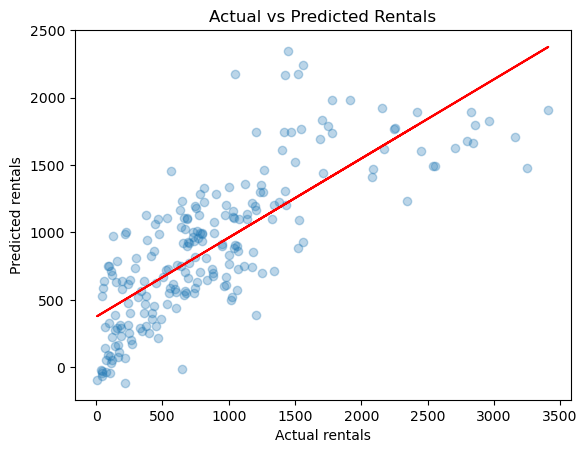

In [15]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.scatter(y_test, predictions, alpha=0.3)
plt.xlabel('Actual rentals')
plt.ylabel('Predicted rentals')
plt.title('Actual vs Predicted Rentals')
z = np.polyfit(y_test, predictions, 1)
p = np.poly1d(z)
plt.plot(y_test,p(y_test),color='red')
plt.show()

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mse = mean_squared_error(y_test, predictions)
print('Mean Squared Error:', mse)

mae = mean_absolute_error(y_test, predictions)
print('Mean Absolute Error:', mae)

rmse = np.sqrt(mse)
print('Root Mean Squared Error:', rmse)

r2 = r2_score(y_test, predictions)
print('R^2 Score:', r2)


Mean Squared Error: 201972.55947035595
Mean Absolute Error: 322.99762918984186
Root Mean Squared Error: 449.4135728595165
R^2 Score: 0.604045473691919
